# Module 6 Lab 1: Query Like an Analyst

**Course:** CS 82A – Data Science  
**Name:** Svetlana Babaeva

### Load the CSVs and Build the Database

In [1]:
import pandas as pd
import sqlite3

print("Pandas and SQLite are ready.")

Pandas and SQLite are ready.


In [2]:
df_orders = pd.read_csv("store_orders.csv")
df_customers = pd.read_csv("store_customers.csv")

print("Orders:", len(df_orders), "rows")
print("Customers:", len(df_customers), "rows")

Orders: 200 rows
Customers: 40 rows


In [3]:
con = sqlite3.connect("store.db")

df_orders.to_sql("orders", con, if_exists="replace", index=False)
df_customers.to_sql("customers", con, if_exists="replace", index=False)

print("Database created successfully.")

Database created successfully.


In [4]:
pd.read_sql("SELECT name FROM sqlite_master", con)

,name
0,orders
1,customers


### First Look, Filter and Sort
Inspect the first five orders, then retrieve orders above $100, sorted by amount from highest to lowest.

In [5]:
print("Step 2: First five orders")
display(pd.read_sql("SELECT * FROM orders LIMIT 5", con))

print("Step 3: Orders above $100, highest first")
display(pd.read_sql("""
    SELECT *
    FROM orders
    WHERE amount > 100
    ORDER BY amount DESC
""", con))

Step 2: First five orders


,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


Step 3: Orders above $100, highest first


,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


### Aggregate by Category
Calculate the number of orders and average order amount for each product category.

In [6]:
category_summary = pd.read_sql("""
    SELECT category,
           COUNT(*) AS n,
           AVG(amount) AS avg_amount
    FROM orders
    GROUP BY category
    ORDER BY avg_amount DESC
""", con)

display(category_summary)

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


# Analyst's Statement
## Electronics has the highest average order amount at $190.57 per order.

### Join for Spend by City
Join the orders and customers tables using customer_id, then calculate total order spending for each city.

In [7]:
city_spend = pd.read_sql("""
    SELECT c.city, SUM(o.amount) AS total_spend
    FROM orders AS o
    JOIN customers AS c
        ON o.customer_id = c.customer_id
    GROUP BY c.city
    ORDER BY total_spend DESC
""", con)

display(city_spend)

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


### The Row-Count Audit
Compare the number of orders before and after the INNER JOIN.

In [8]:
print("Original orders:")
display(pd.read_sql("""
    SELECT COUNT(*) AS original_orders
    FROM orders
""", con))

print("Orders after INNER JOIN:")
display(pd.read_sql("""
    SELECT COUNT(*) AS joined_orders
    FROM orders AS o
    JOIN customers AS c
        ON o.customer_id = c.customer_id
""", con))

Original orders:


,original_orders
0,200


Orders after INNER JOIN:


,joined_orders
0,195


# The Row-Count Audit
## I started with 200 orders, but after the INNER JOIN, I got only 195. Five orders have customer IDs that are not in the customers table, so the INNER JOIN excluded them.

### Chart a Query Result
Create a bar chart of total spending by city using the SQL query result from Step 5.

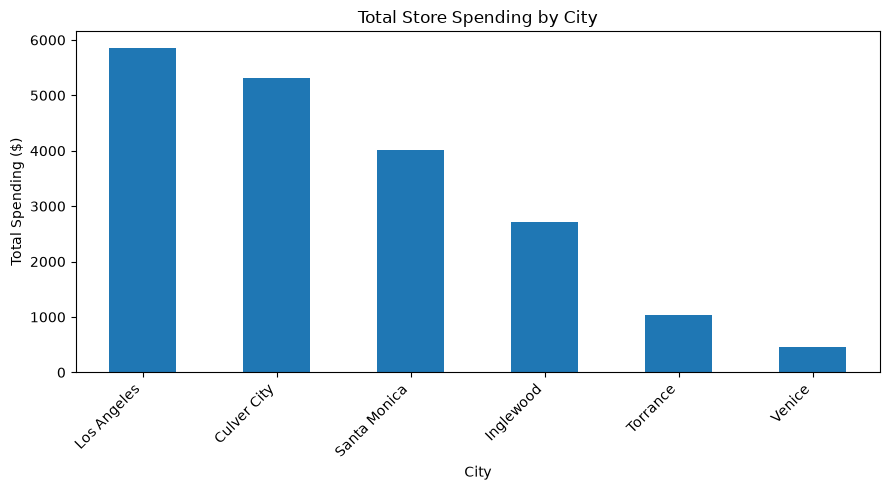

In [9]:
import matplotlib.pyplot as plt

city_spend.plot(
    kind="bar",
    x="city",
    y="total_spend",
    legend=False,
    figsize=(9, 5)
)

plt.title("Total Store Spending by City")
plt.xlabel("City")
plt.ylabel("Total Spending ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Own Business Question
## Which product brings in the most money?

In [10]:
product_sales = pd.read_sql("""
    SELECT product, SUM(amount) AS total_sales
    FROM orders
    GROUP BY product
    ORDER BY total_sales DESC
    LIMIT 1
""", con)

In [11]:
display(product_sales)

,product,total_sales
0,headset,4902.3


## I found that headsets bring in the most money, with total sales of $4,902.30.

# Ethics Note and Safe Push

## I would not share customer names, IDs, or individual records publicly. Instead, I would share total sales by city or category. This would help protect customer privacy while still showing useful information.